In [1]:
import numpy as np 
import pandas as pd 

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

In [2]:
import pandas as pd
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

df = pd.read_csv("emails.csv")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5172 entries, 0 to 5171
Columns: 3002 entries, Email No. to Prediction
dtypes: int64(3001), object(1)
memory usage: 118.5+ MB


In [3]:
print(df.head())

  Email No.  the  to  ect  and  for  of    a  you  hou  ...  connevey  jay  \
0   Email 1    0   0    1    0    0   0    2    0    0  ...         0    0   
1   Email 2    8  13   24    6    6   2  102    1   27  ...         0    0   
2   Email 3    0   0    1    0    0   0    8    0    0  ...         0    0   
3   Email 4    0   5   22    0    5   1   51    2   10  ...         0    0   
4   Email 5    7   6   17    1    5   2   57    0    9  ...         0    0   

   valued  lay  infrastructure  military  allowing  ff  dry  Prediction  
0       0    0               0         0         0   0    0           0  
1       0    0               0         0         0   1    0           0  
2       0    0               0         0         0   0    0           0  
3       0    0               0         0         0   0    0           0  
4       0    0               0         0         0   1    0           0  

[5 rows x 3002 columns]


In [4]:
# Separate features and target

X = df.drop(['Email No.', 'Prediction'], axis=1)
y = df['Prediction']

print("Features:", X.shape)
print("Target:", y.shape)

print("\nClass Distribution:")
print(y.value_counts())

Features: (5172, 3000)
Target: (5172,)

Class Distribution:
Prediction
0    3672
1    1500
Name: count, dtype: int64


In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

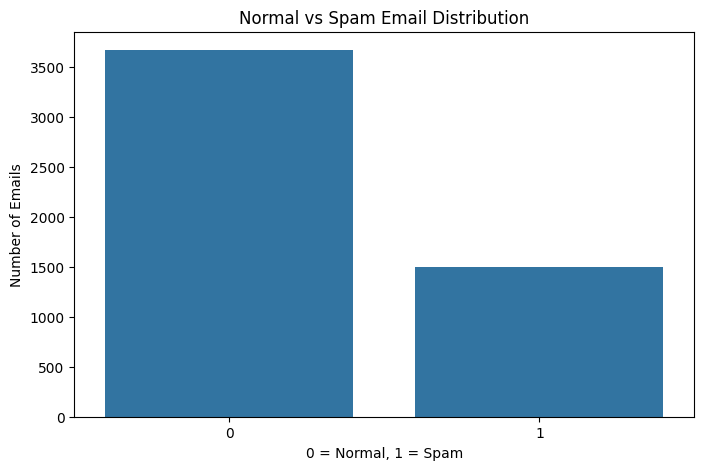

In [9]:
plt.figure(figsize=(8, 5))

sns.countplot(x='Prediction', data=df)

plt.title('Normal vs Spam Email Distribution')
plt.xlabel('0 = Normal, 1 = Spam')
plt.ylabel('Number of Emails')
plt.show()

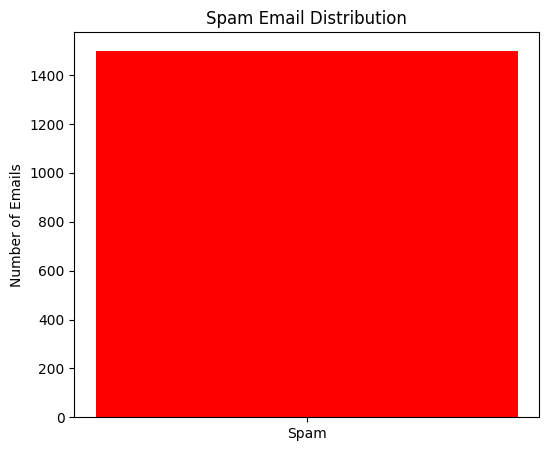

Total Spam Emails: 1500


In [25]:
spam_count = (df['Prediction'] == 1).sum()

plt.figure(figsize=(6, 5))
plt.bar(['Spam'], [spam_count], color='red')
plt.title('Spam Email Distribution')
plt.ylabel('Number of Emails')
plt.show()

print("Total Spam Emails:", spam_count)

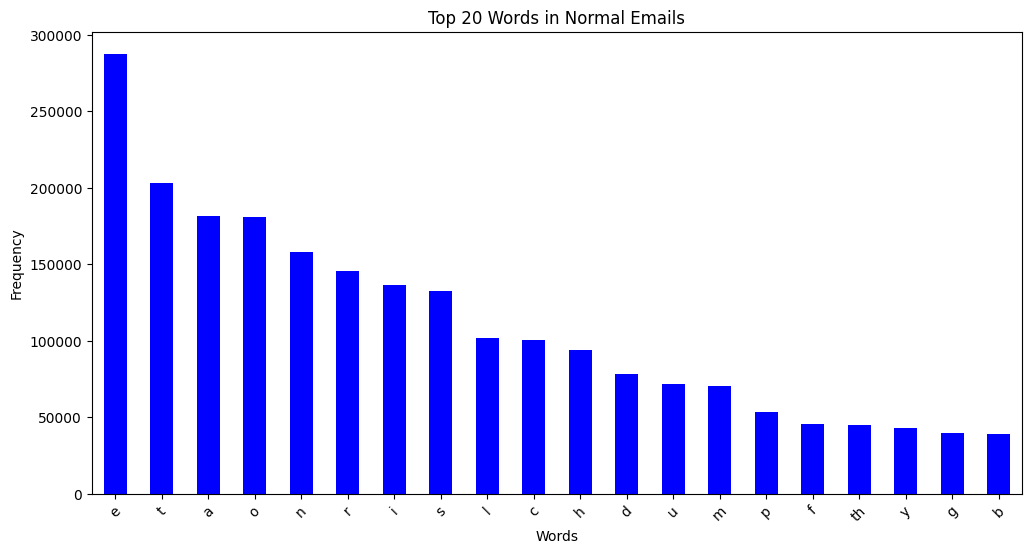

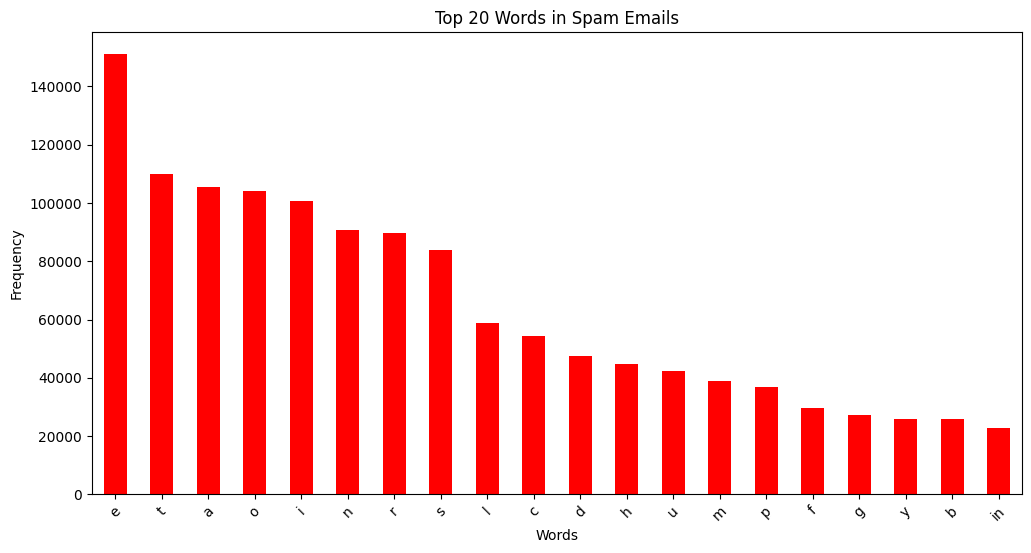

In [26]:
# Most frequent words in Ham and Spam emails

import matplotlib.pyplot as plt
import seaborn as sns

# Ham = 0
ham_words = X[y == 0].sum().sort_values(ascending=False).head(20)

# Spam = 1
spam_words = X[y == 1].sum().sort_values(ascending=False).head(20)

# Ham word frequency
plt.figure(figsize=(12, 6))
ham_words.plot(kind='bar', color='blue')
plt.title('Top 20 Words in Normal Emails')
plt.xlabel('Words')
plt.ylabel('Frequency')
plt.xticks(rotation=45)
plt.show()

# Spam word frequency
plt.figure(figsize=(12, 6))
spam_words.plot(kind='bar', color='red')
plt.title('Top 20 Words in Spam Emails')
plt.xlabel('Words')
plt.ylabel('Frequency')
plt.xticks(rotation=45)
plt.show()

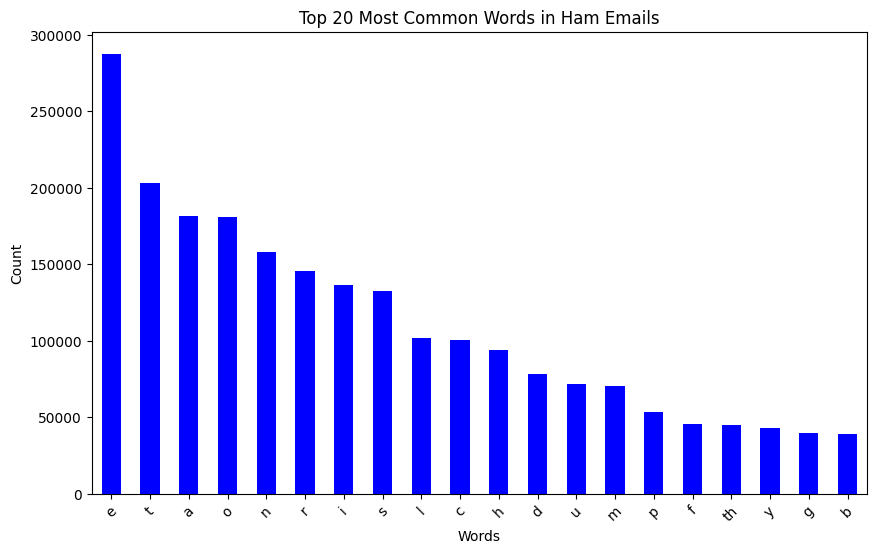

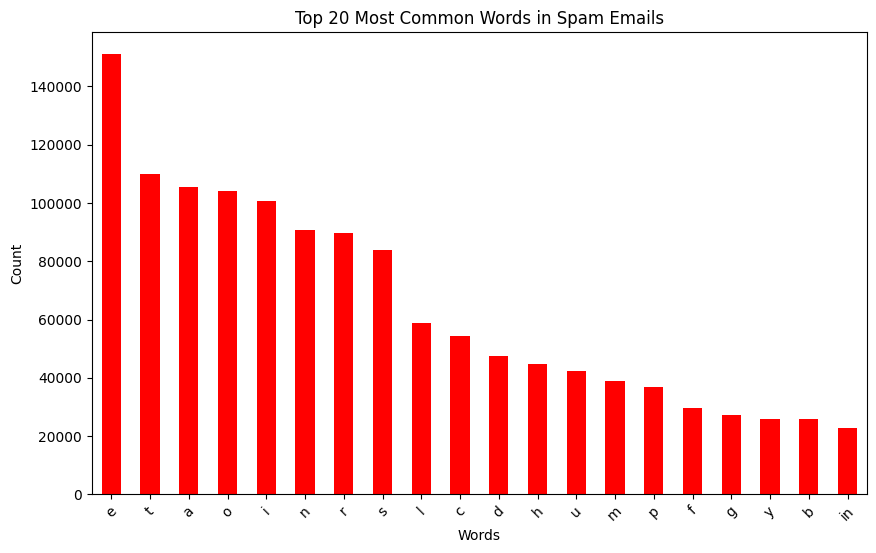

In [14]:
# Find the 20 most common words in Ham and Spam emails

import matplotlib.pyplot as plt

# Separate word-frequency features
X = df.drop(['Email No.', 'Prediction'], axis=1)

# Ham emails (Prediction = 0)
ham_word_count = X[df['Prediction'] == 0].sum().sort_values(ascending=False).head(20)

# Spam emails (Prediction = 1)
spam_word_count = X[df['Prediction'] == 1].sum().sort_values(ascending=False).head(20)

# Plot Ham words
plt.figure(figsize=(10, 6))
ham_word_count.plot(kind='bar', color='blue')
plt.title('Top 20 Most Common Words in Ham Emails')
plt.ylabel('Count')
plt.xlabel('Words')
plt.xticks(rotation=45)
plt.show()

# Plot Spam words
plt.figure(figsize=(10, 6))
spam_word_count.plot(kind='bar', color='red')
plt.title('Top 20 Most Common Words in Spam Emails')
plt.ylabel('Count')
plt.xlabel('Words')
plt.xticks(rotation=45)
plt.show()

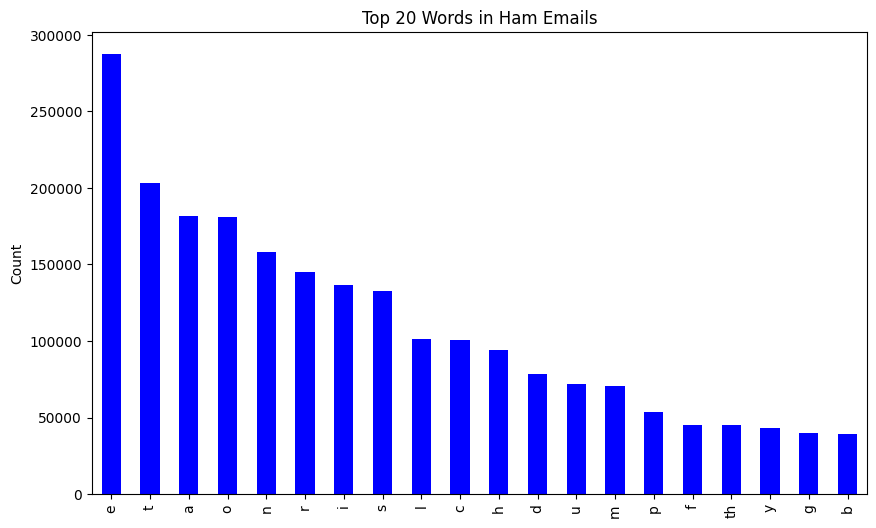

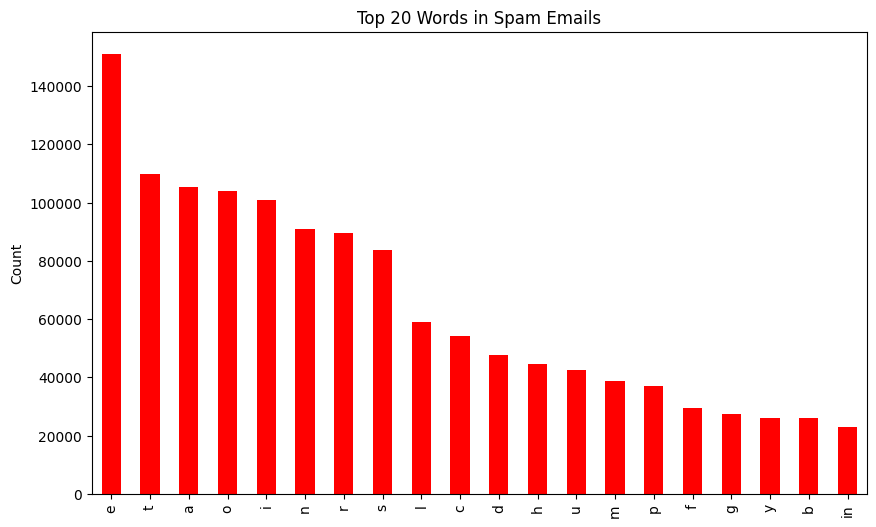

In [17]:
# Top 20 words in Ham and Spam emails

X = df.drop(['Email No.', 'Prediction'], axis=1)

ham_bigram_count = X[df['Prediction'] == 0].sum().nlargest(20)
spam_bigram_count = X[df['Prediction'] == 1].sum().nlargest(20)

# Ham plot
plt.figure(figsize=(10, 6))
ham_bigram_count.plot(kind='bar', color='blue')
plt.title('Top 20 Words in Ham Emails')
plt.ylabel('Count')
plt.show()

# Spam plot
plt.figure(figsize=(10, 6))
spam_bigram_count.plot(kind='bar', color='red')
plt.title('Top 20 Words in Spam Emails')
plt.ylabel('Count')
plt.show()

In [18]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [19]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
y_pred_knn = knn.predict(X_test)

In [20]:
svm = SVC(kernel='linear')
svm.fit(X_train, y_train)
y_pred_svm = svm.predict(X_test)

In [21]:
print("KNN Classification Report:\n", classification_report(y_test, y_pred_knn))
print("SVM Classification Report:\n", classification_report(y_test, y_pred_svm))


KNN Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.87      0.90      1097
           1       0.73      0.83      0.78       455

    accuracy                           0.86      1552
   macro avg       0.83      0.85      0.84      1552
weighted avg       0.87      0.86      0.86      1552

SVM Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.97      0.97      1097
           1       0.92      0.93      0.93       455

    accuracy                           0.96      1552
   macro avg       0.95      0.95      0.95      1552
weighted avg       0.96      0.96      0.96      1552



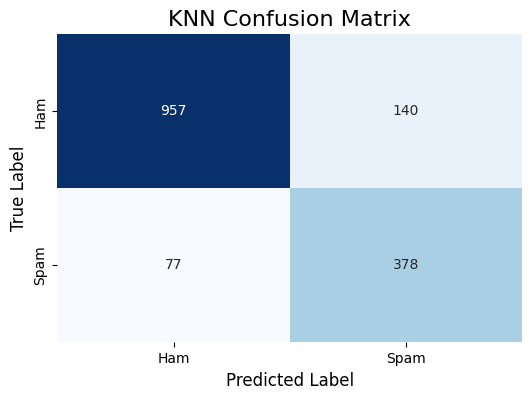

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

def plot_confusion_matrix(cm, model_name):
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, 
                xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'])
    plt.title(f'{model_name} Confusion Matrix', fontsize=16)
    plt.xlabel('Predicted Label', fontsize=12)
    plt.ylabel('True Label', fontsize=12)
    plt.show()

cm_knn = confusion_matrix(y_test, y_pred_knn)
plot_confusion_matrix(cm_knn, 'KNN')


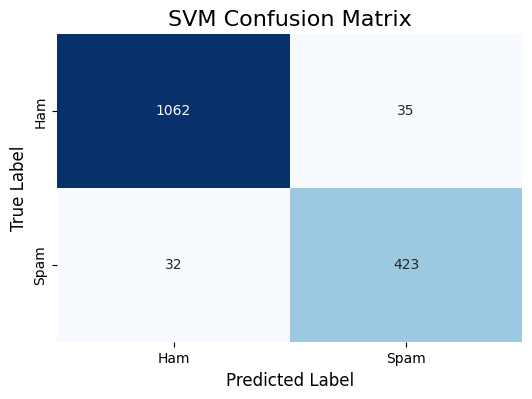

In [23]:
cm_svm = confusion_matrix(y_test, y_pred_svm)
plot_confusion_matrix(cm_svm, 'SVM')